# EDA: OULAD dibanding Moodle Sekolah

Skenario A dan B berasal dari satu sekolah. Dua skenario dipakai karena semester belum selesai, sehingga nilai akhir belum ada:

- **Skenario A:** fitur sampai hari ke-45, label dari semua kuis dan tugas. Optimistis, karena nilai yang sama ada di fitur dan label.
- **Skenario B:** fitur sampai hari ke-28, label hanya dari kuis dan tugas yang dibuka setelahnya. Dipakai sebagai acuan.

### Cara membaca notebook ini
- **Baris** berarti satu siswa di satu mapel, bukan satu siswa. Satu siswa bisa muncul di beberapa baris.
- **Koma adalah desimal dan titik adalah ribuan.** Contoh: `72,59` berarti tujuh puluh dua koma lima sembilan, sedangkan `32.593` berarti tiga puluh dua ribu lebih.
- **OULAD** berasal dari mahasiswa jarak jauh, sedangkan **Skenario A dan B** berasal dari siswa SMK. Batas waktu datanya berbeda: hari ke-60, ke-45, dan ke-28.
- Setiap bagian diakhiri penjelasan hasilnya. Batasan perbandingan dirangkum di bagian 7.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import roc_auc_score
from ews_features import FEATURE_COLS, build_features
from moodle_dump import load_tables
from moodle_features import build_dataset

BIRU, ORANYE, AQUA, UNGU = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
INK, INK2, GRID, PERMUKAAN = "#0b0b0b", "#52514e", "#e7e6e1", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": PERMUKAAN, "axes.facecolor": PERMUKAAN, "savefig.facecolor": PERMUKAAN,
    "figure.dpi": 120, "font.family": "DejaVu Sans", "font.size": 10, "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": .7, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2, "legend.frameon": False})
def id_angka(v, d=2):
    """Format Indonesia: titik untuk ribuan, koma untuk desimal."""
    return "—" if pd.isna(v) else f"{v:,.{d}f}".translate(str.maketrans(",.", ".,"))
pd.set_option("display.float_format", id_angka)

In [2]:
# Data OULAD dibaca dari CSV asli, lalu dihitung dengan fungsi fitur yang sama dengan prototipe
D = Path("baseline_oulad")
info = pd.read_csv(D / "studentInfo.csv")
vle = pd.read_csv(D / "studentVle.csv", usecols=["code_module", "code_presentation", "id_student", "id_site", "date", "sum_click"])
sa = pd.read_csv(D / "studentAssessment.csv")
ases = pd.read_csv(D / "assessments.csv")
oulad = build_features(info, vle, sa, ases)

# Skenario A dari ekspor anonim; Skenario B dihitung dari cache tabel Moodle, identitas langsung dibuang
KOLOM = FEATURE_COLS + ["is_at_risk"]
csv_a = pd.read_csv("data_kokar/fitur_kokar_hari45_anonim.csv")
sek_a = csv_a[KOLOM].copy()
tabel = load_tables("../exp_kokar.sql", "data_kokar/tables")
sek_b = build_dataset(tabel, cut_off=28, label_after_cutoff=True)[KOLOM].copy()
print(f"OULAD {id_angka(len(oulad), 0)} baris | Skenario A {id_angka(len(sek_a), 0)} baris | Skenario B {id_angka(len(sek_b), 0)} baris")

OULAD 32.593 baris | Skenario A 2.216 baris | Skenario B 1.753 baris


## 1. Angka dasar

In [3]:
def ringkas(d):
    return {"Baris": len(d), "Berisiko (%)": d.is_at_risk.mean() * 100, "Median klik": d.total_clicks.median(),
            "Median hari aktif": d.active_days.median(), "Median hari tidak aktif": d.days_inactive.median(),
            "Median durasi (jam)": d.course_duration_hours.median(), "Baris tanpa klik (%)": (d.total_clicks == 0).mean() * 100}
desimal = {"Baris": 0, "Berisiko (%)": 1, "Median klik": 0, "Median hari aktif": 0, "Median hari tidak aktif": 0, "Median durasi (jam)": 2, "Baris tanpa klik (%)": 1}
tabel_dasar = pd.DataFrame({"OULAD (hari ke-60)": ringkas(oulad), "Skenario A (hari ke-45)": ringkas(sek_a), "Skenario B (hari ke-28)": ringkas(sek_b)})
tabel_dasar.apply(lambda baris: baris.map(lambda v: id_angka(v, desimal[baris.name])), axis=1)

,OULAD (hari ke-60),Skenario A (hari ke-45),Skenario B (hari ke-28)
Baris,32.593,2.216,1.753
Berisiko (%),"52,8","81,9","83,3"
Median klik,281,20,6
Median hari aktif,18,1,1
Median hari tidak aktif,4,29,18
Median durasi (jam),"6,78","0,11","0,05"
Baris tanpa klik (%),"10,7","30,1","40,5"


**Cara baca.** Tabel ini merangkum kondisi tiap data sampai batas waktunya.
- **Sekolah jauh lebih sepi daripada OULAD.** Median klik 281 pada OULAD, 20 pada Skenario A, dan 6 pada Skenario B. Median hari aktif 18 berbanding 1.
- **Sebagian besar baris sekolah berlabel berisiko:** 81,9% dan 83,3%, sedangkan OULAD 52,8%.
- **Perhatikan batas waktunya.** Skenario B hanya melihat 28 hari, jadi kliknya memang lebih sedikit daripada Skenario A. Bagian 7 menjelaskan kenapa baris durasi dan label tidak setara.

## 2. Baris tanpa klik

,Baris tanpa klik,Porsi (%),"Berisiko, tanpa klik (%)","Berisiko, ada klik (%)"
Data,,,,
OULAD,3484,"10,69","98,62","47,31"
Skenario A,668,"30,14","99,70","74,16"
Skenario B,710,"40,50","96,06","74,59"


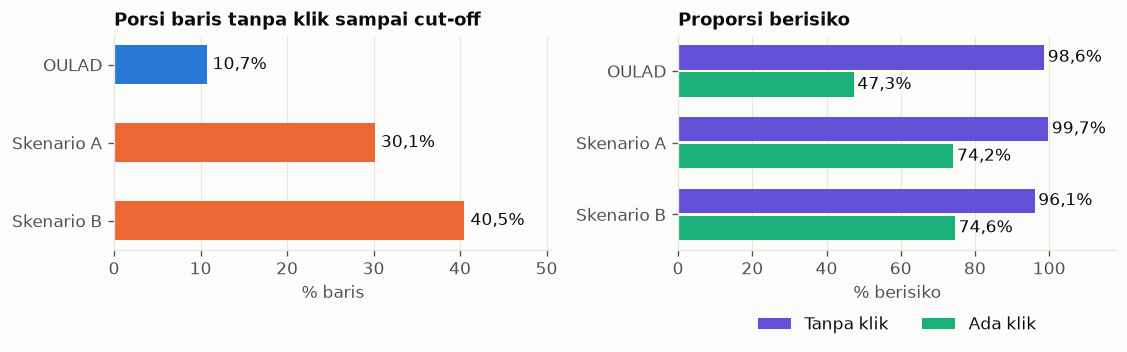

In [4]:
data = {"OULAD": oulad, "Skenario A": sek_a, "Skenario B": sek_b}
warna = {"OULAD": BIRU, "Skenario A": ORANYE, "Skenario B": ORANYE}
rows = []
for k, d in data.items():
    nol = d.total_clicks == 0
    rows.append({"Data": k, "Baris tanpa klik": int(nol.sum()), "Porsi (%)": nol.mean() * 100,
                 "Berisiko, tanpa klik (%)": d.is_at_risk[nol].mean() * 100, "Berisiko, ada klik (%)": d.is_at_risk[~nol].mean() * 100})
nol_tbl = pd.DataFrame(rows).set_index("Data"); display(nol_tbl)

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
kunci = list(data)
y = np.arange(3)[::-1]
ax[0].barh(y, nol_tbl["Porsi (%)"], color=[warna[k] for k in kunci], height=.5)
koma = lambda v: f"{v:.1f}%".replace(".", ",")
for yi, v in zip(y, nol_tbl["Porsi (%)"]): ax[0].text(v + .7, yi, koma(v), va="center")
ax[0].set(yticks=y, yticklabels=kunci, xlabel="% baris", title="Porsi baris tanpa klik sampai cut-off", xlim=(0, nol_tbl["Porsi (%)"].max() * 1.25)); ax[0].grid(axis="y", visible=False)
h = .34
ax[1].barh(y + h / 2 + .02, nol_tbl["Berisiko, tanpa klik (%)"], height=h, color=UNGU, label="Tanpa klik")
ax[1].barh(y - h / 2 - .02, nol_tbl["Berisiko, ada klik (%)"], height=h, color=AQUA, label="Ada klik")
for yi, a, b in zip(y, nol_tbl["Berisiko, tanpa klik (%)"], nol_tbl["Berisiko, ada klik (%)"]):
    ax[1].text(a + 1, yi + h / 2 + .02, koma(a), va="center"); ax[1].text(b + 1, yi - h / 2 - .02, koma(b), va="center")
ax[1].set(yticks=y, yticklabels=kunci, xlabel="% berisiko", title="Proporsi berisiko", xlim=(0, 118)); ax[1].grid(axis="y", visible=False)
ax[1].legend(loc="upper center", bbox_to_anchor=(.5, -.24), ncol=2)
fig.tight_layout(); plt.show()

**Cara baca.** "Tanpa klik" berarti baris itu tidak punya aktivitas sampai batas waktu.
- Porsinya 10,7% pada OULAD, 30,1% pada Skenario A, dan 40,5% pada Skenario B.
- Hampir semua baris tanpa klik berlabel berisiko (96,1–99,7%). Jadi tidak adanya klik adalah tanda yang sangat kuat.
- Baris yang ada klik pun masih banyak berisiko di sekolah (sekitar 74%), jauh di atas OULAD (47,3%). Artinya, membuka Moodle saja belum cukup untuk aman.

## 3. Aktivitas per minggu

OULAD                        Sekolah               
       aktif (% baris) klik per baris aktif (% baris) klik per baris
minggu                                                              
0                72,59          61,76           24,95           7,14
1                71,08          55,15           38,13           8,96
2                73,09          70,78           34,61           5,15
3                67,91          51,04           15,66           1,29
4                66,46          46,19           20,98           2,77
5                62,47          37,70           22,83           3,38
6                62,09          41,44           10,92           1,14
7                61,02          39,50            6,45           0,41
8                56,42          28,54            6,59           0,45
9                53,87          32,58            2,93           0,14
10               44,62          19,85            4,87           1,33
11               41,91          17,73            4,69           1,21
12               49,80          25,52            2,57           0,66
13               52,00          30,45            3,75           0,55

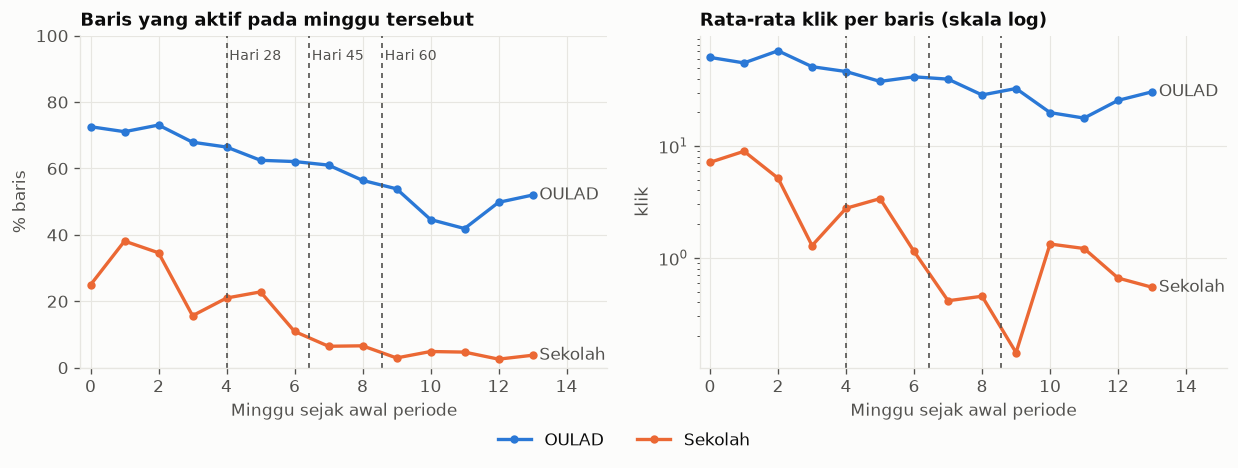

In [5]:
MINGGU = np.arange(0, 14)
v = vle[vle.date >= 0].assign(minggu=lambda x: x.date // 7)
v = v[v.minggu.isin(MINGGU)]
oul_w = pd.DataFrame({
    "aktif": v.drop_duplicates(["code_module", "code_presentation", "id_student", "minggu"]).groupby("minggu").size() / len(info) * 100,
    "klik": v.groupby("minggu").sum_click.sum() / len(info)})

pasangan = csv_a[["userid", "courseid"]].drop_duplicates()
log = tabel["mdl_logstore_standard_log"][["userid", "courseid", "timecreated"]].merge(pasangan, on=["userid", "courseid"])
log["t0"] = log.courseid.map(tabel["mdl_course"].set_index("id").startdate)
log["minggu"] = (log.timecreated - log.t0) // (7 * 86400)
log = log[log.minggu.isin(MINGGU)]
sek_w = pd.DataFrame({
    "aktif": log.drop_duplicates(["userid", "courseid", "minggu"]).groupby("minggu").size() / len(pasangan) * 100,
    "klik": log.groupby("minggu").size() / len(pasangan)})
oul_w, sek_w = oul_w.reindex(MINGGU, fill_value=0), sek_w.reindex(MINGGU, fill_value=0)
del log
display(pd.concat({"OULAD": oul_w, "Sekolah": sek_w}, axis=1).rename(columns={"aktif": "aktif (% baris)", "klik": "klik per baris"}))

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.7))
for a, kol, judul, lab in [(ax[0], "aktif", "Baris yang aktif pada minggu tersebut", "% baris"), (ax[1], "klik", "Rata-rata klik per baris (skala log)", "klik")]:
    a.plot(MINGGU, oul_w[kol], color=BIRU, marker="o", ms=4, label="OULAD")
    a.plot(MINGGU, sek_w[kol], color=ORANYE, marker="o", ms=4, label="Sekolah")
    a.set(title=judul, xlabel="Minggu sejak awal periode", ylabel=lab)
    a.text(13.2, oul_w[kol].iloc[-1], "OULAD", color=INK2, va="center"); a.text(13.2, max(sek_w[kol].iloc[-1], .001), "Sekolah", color=INK2, va="center")
    a.set_xlim(-.3, 15.2)
ax[1].set_yscale("log")
ax[0].set_ylim(0, 100)
for hari, nama in [(28, "Hari 28"), (45, "Hari 45"), (60, "Hari 60")]:
    for a in ax: a.axvline(hari / 7, color=INK2, lw=1, ls=(0, (3, 3)))
    ax[0].text(hari / 7 + .08, 96, nama, color=INK2, fontsize=8.5, va="top")
fig.legend(*ax[0].get_legend_handles_labels(), loc="lower center", ncol=2, bbox_to_anchor=(.5, -.06))
fig.tight_layout(); plt.show()

**Cara baca.** `aktif (% baris)` adalah persen baris yang minimal sekali aktif pada minggu itu. `klik per baris` adalah rata-rata klik per baris pada minggu itu, dan baris yang tidak aktif ikut dihitung sebagai 0. Keduanya bukan satuan ribu.

Contoh minggu 9: pada sekolah, `2,93` berarti 2,93% baris aktif dan `0,14` berarti rata-rata 0,14 klik. Pada OULAD, `53,87` berarti 53,87% baris aktif dan `32,58` berarti rata-rata 32,58 klik.

**Temuannya.** Aktivitas sekolah memuncak pada minggu 1 (38,13% baris), lalu turun ke 2,57–4,87% sejak minggu 9. OULAD lebih stabil dan masih 52,00% pada minggu 13. Inilah alasan model perlu dilatih ulang dengan data sekolah. Garis putus-putus menandai batas waktu tiap data.

## 4. Total klik menurut label

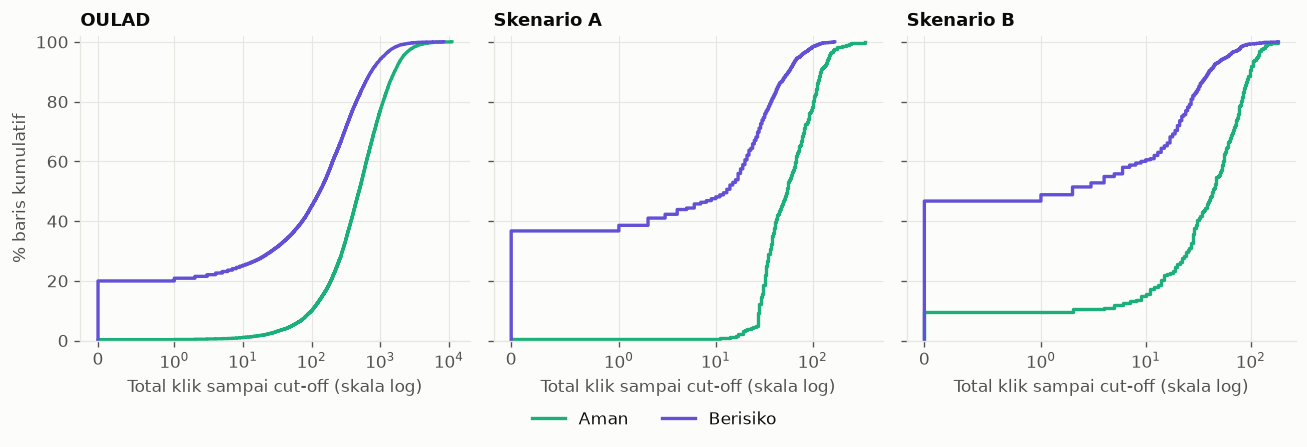

,OULAD,Skenario A,Skenario B
Median klik aman,490,54,44
Median klik berisiko,132,13,2


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.5), sharey=True)
for a, (k, d) in zip(ax, data.items()):
    for lbl, wr, nama in [(0, AQUA, "Aman"), (1, UNGU, "Berisiko")]:
        x = np.sort(d.total_clicks[d.is_at_risk == lbl].values)
        a.step(x, np.arange(1, len(x) + 1) / len(x) * 100, where="post", color=wr, label=nama)
    a.set_xscale("symlog", linthresh=1); a.set(title=k, xlabel="Total klik sampai cut-off (skala log)", ylim=(0, 102))
ax[0].set_ylabel("% baris kumulatif")
fig.legend(*ax[0].get_legend_handles_labels(), loc="lower center", ncol=2, bbox_to_anchor=(.5, -.07))
fig.tight_layout(); plt.show()
pd.DataFrame({k: d.groupby("is_at_risk").total_clicks.median().rename({0: "Median klik aman", 1: "Median klik berisiko"}) for k, d in data.items()}).rename_axis(None).map(lambda v: id_angka(v, 0))

**Cara baca kurva.** Pilih satu nilai klik pada sumbu X, lalu lihat sumbu Y: itu persen baris yang kliknya sama atau kurang dari nilai tersebut. Kurva yang berada lebih ke kiri berarti kliknya lebih sedikit.

**Temuannya.** Pada ketiga data, kurva berisiko berada di kiri kurva aman, jadi siswa berisiko memang lebih sedikit klik. Median aman dan berisiko: 490 dan 132 pada OULAD, 54 dan 13 pada Skenario A, 44 dan 2 pada Skenario B.

## 5. Daya pisah fitur tunggal

ROC-AUC satu fitur tanpa model.

,OULAD,Skenario A,Skenario B
total_clicks,"0,764","0,862","0,809"
lesson_attempts_count,"0,554","0,817","0,805"
unique_sites_accessed,"0,729","0,782","0,799"
lesson_time_spent_min,"0,554","0,842","0,797"
active_days,"0,781","0,786","0,791"
course_duration_hours,"0,767","0,800","0,785"
lesson_avg_score,"0,568","0,862","0,774"
days_inactive,"0,802","0,713","0,773"
avg_score,"0,782","0,867","0,761"
min_score,"0,767","0,850","0,747"


,OULAD,Skenario A,Skenario B
0,"score_rel_to_module = 0,808","avg_score = 0,867","total_clicks = 0,809"
1,"days_inactive = 0,802","lesson_avg_score = 0,862","lesson_attempts_count = 0,805"
2,"avg_score = 0,782","total_clicks = 0,862","unique_sites_accessed = 0,799"


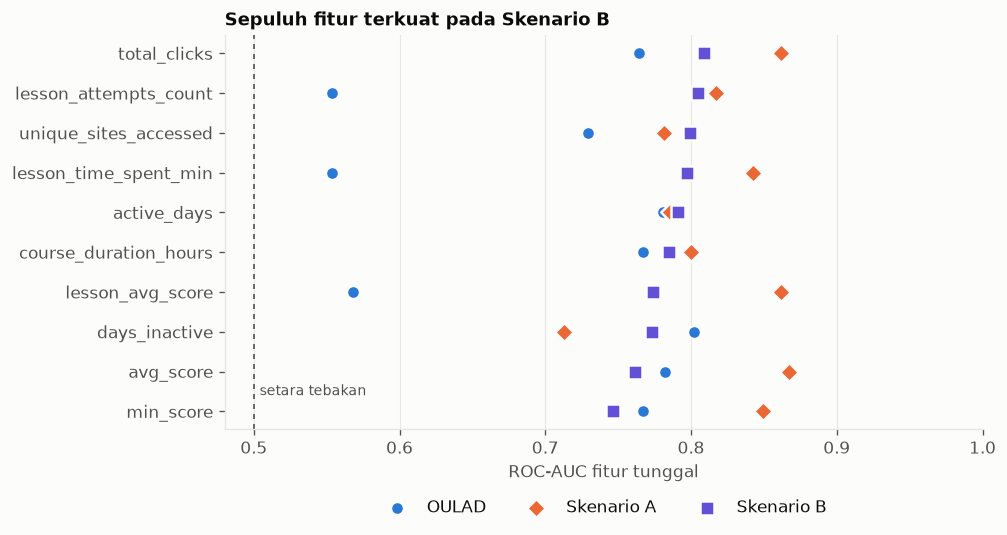

In [7]:
def auc1(d, f):
    if d[f].nunique() < 2: return np.nan
    a = roc_auc_score(d.is_at_risk, d[f]); return max(a, 1 - a)
auc = pd.DataFrame({k: {f: auc1(d, f) for f in FEATURE_COLS} for k, d in data.items()})
display(auc.sort_values("Skenario B", ascending=False).head(12).map(lambda v: id_angka(v, 3)))
display(pd.DataFrame({k: auc[k].sort_values(ascending=False).head(3).map(lambda v: id_angka(v, 3)).reset_index().agg(" = ".join, axis=1) for k in auc}))
pilih = auc.sort_values("Skenario B", ascending=False).head(10).index[::-1]
fig, a = plt.subplots(figsize=(8.5, 4.6))
y = np.arange(len(pilih))
for k, wr, mk in [("OULAD", BIRU, "o"), ("Skenario A", ORANYE, "D"), ("Skenario B", UNGU, "s")]:
    a.scatter(auc.loc[pilih, k], y, s=62, color=wr, marker=mk, edgecolors=PERMUKAAN, linewidths=1.5, label=k, zorder=3)
a.axvline(.5, color=INK2, lw=1, ls=(0, (3, 3))); a.text(.504, .5, "setara tebakan", color=INK2, fontsize=8.5, va="center")
a.set(yticks=y, yticklabels=pilih, xlabel="ROC-AUC fitur tunggal", title="Sepuluh fitur terkuat pada Skenario B", xlim=(.48, 1)); a.grid(axis="y", visible=False)
a.legend(loc="upper center", bbox_to_anchor=(.5, -.14), ncol=3)
fig.tight_layout(); plt.show()

**Cara baca.** ROC-AUC di sini mengukur kemampuan satu fitur memisahkan baris berisiko dan aman: 0,5 setara tebakan, 1 berarti sempurna. Nilainya dihitung sebagai `max(a, 1 - a)`, jadi hanya menunjukkan kekuatan, bukan arah. Nilai tinggi tidak memberi tahu apakah fitur menaikkan atau menurunkan risiko.

**Temuannya.**
- Skenario B menjadi acuan. Fitur terkuatnya `total_clicks` (0,809), `lesson_attempts_count` (0,805), dan `unique_sites_accessed` (0,799).
- Fitur nilai lebih tinggi pada Skenario A karena nilai yang sama ikut membentuk label. Contoh `avg_score`: 0,867 pada Skenario A dan 0,761 pada Skenario B.
- Fitur kuis jauh lebih berguna di sekolah. `lesson_attempts_count` hanya 0,554 pada OULAD, tetapi 0,805 pada Skenario B.

## 6. Korelasi antarfitur (Spearman)

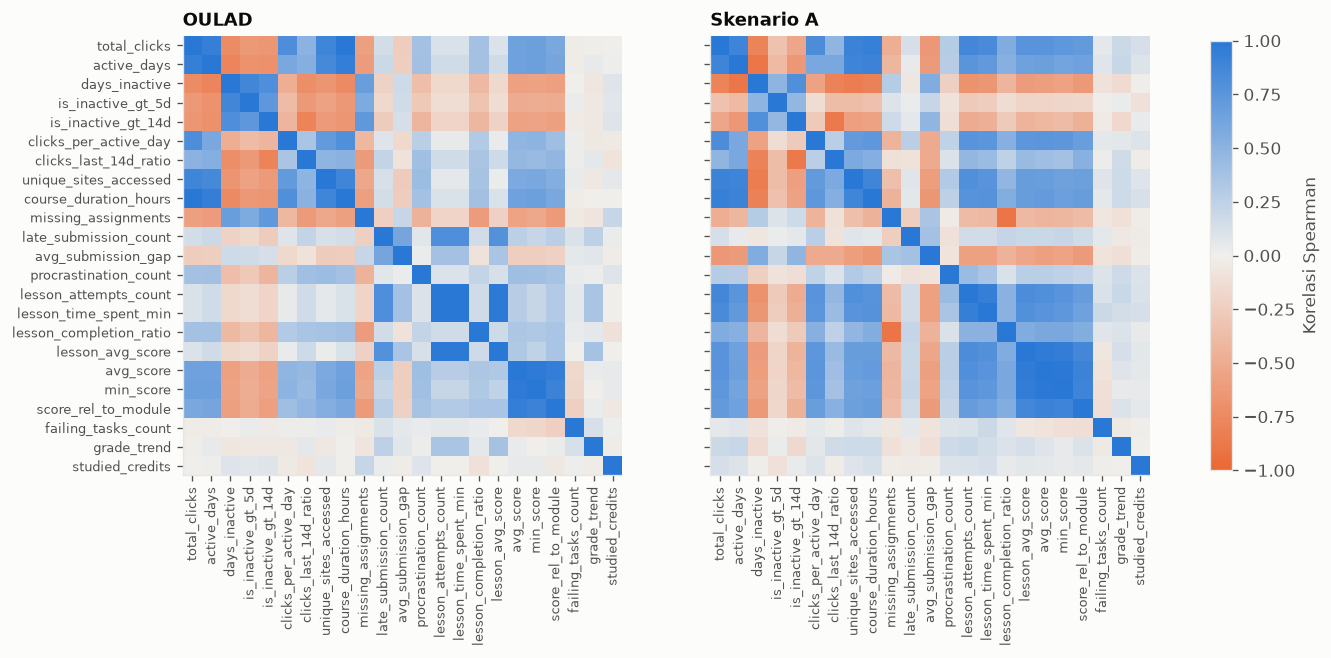

Pasangan fitur paling berkorelasi, OULAD


,Fitur 1,Fitur 2,Spearman
0,lesson_attempts_count,lesson_time_spent_min,"1,000"
1,total_clicks,course_duration_hours,"0,997"
2,lesson_attempts_count,lesson_avg_score,"0,977"
3,lesson_time_spent_min,lesson_avg_score,"0,977"
4,avg_score,min_score,"0,975"
5,avg_score,score_rel_to_module,"0,944"
6,active_days,course_duration_hours,"0,944"
7,total_clicks,active_days,"0,934"


Pasangan fitur paling berkorelasi, Skenario A


,Fitur 1,Fitur 2,Spearman
0,avg_score,min_score,"0,991"
1,lesson_avg_score,avg_score,"0,966"
2,lesson_avg_score,min_score,"0,948"
3,lesson_attempts_count,lesson_time_spent_min,"0,931"
4,total_clicks,course_duration_hours,"0,929"
5,active_days,course_duration_hours,"0,906"
6,avg_score,score_rel_to_module,"0,900"
7,total_clicks,unique_sites_accessed,"0,900"


In [8]:
fitur = [f for f in FEATURE_COLS if f != "num_of_prev_attempts"]
peta = LinearSegmentedColormap.from_list("div", [ORANYE, "#f0efec", BIRU])
korel = {"OULAD": oulad[fitur].corr("spearman"), "Skenario A": sek_a[fitur].corr("spearman")}
fig, ax = plt.subplots(1, 2, figsize=(13, 6.2), sharey=True)
for a, (k, c) in zip(ax, korel.items()):
    im = a.imshow(c.fillna(0), cmap=peta, vmin=-1, vmax=1)
    a.set(title=k, xticks=range(len(fitur)), yticks=range(len(fitur))); a.set_xticklabels(fitur, rotation=90, fontsize=8); a.set_yticklabels(fitur, fontsize=8); a.grid(False)
fig.colorbar(im, ax=ax, shrink=.75, label="Korelasi Spearman")
plt.show()
def pasangan_top(c, n=8):
    s = c.where(np.triu(np.ones(c.shape, bool), 1)).stack().sort_values(key=np.abs, ascending=False).head(n)
    return s.rename("Spearman").reset_index().rename(columns={"level_0": "Fitur 1", "level_1": "Fitur 2"})
for nama, c in korel.items():
    print(f"Pasangan fitur paling berkorelasi, {nama}")
    display(pasangan_top(c).assign(Spearman=lambda t: t.Spearman.map(lambda v: id_angka(v, 3))))

**Cara baca.** Biru berarti dua fitur naik bersama, oranye berarti berlawanan, dan warna pucat berarti hampir tidak berhubungan. Nilai mendekati 1 atau -1 berarti kedua fitur membawa informasi yang mirip.

**Temuannya.**
- Dua korelasi tertinggi OULAD berasal dari cara hitungnya, bukan dari perilaku mahasiswa: `lesson_time_spent_min` adalah jumlah percobaan × 25 menit, dan `course_duration_hours` adalah klik × 1,5 menit dengan batas 120 menit per hari.
- Pada sekolah, `avg_score` dan `min_score` sangat mirip (0,991).
- Karena banyak fitur saling mirip, bobot fitur pada model dapat terbagi di antara fitur tersebut. Jadi urutan bobot fitur tidak boleh dibaca sebagai pengaruh yang berdiri sendiri.

## 7. Batasan perbandingan

Perhitungan notebook ini sudah diperiksa ulang secara terpisah. Rata-rata klik mingguan sekolah cocok dengan fitur `total_clicks` (rata-rata 28,99 per baris sampai hari ke-45), tidak ada nilai kosong pada fitur, dan satu-satunya fitur konstan pada sekolah adalah `num_of_prev_attempts`. Perbandingan OULAD dan sekolah tetap perlu dibaca dengan batasan berikut:

| Aspek | OULAD | Sekolah | Akibatnya |
|---|---|---|---|
| Label berisiko | Hasil akhir `Fail` atau `Withdrawn` | Nilai sementara di bawah KKM 75, tidak dikerjakan dihitung 0 | Persen berisiko tidak setara secara langsung |
| Satuan klik | `sum_click` | Satu event log dihitung satu klik | Besar klik hanya perbandingan kasar |
| Durasi belajar | Estimasi 1,5 menit per klik, maksimal 120 menit per hari | Dihitung dari sesi, jeda lebih dari 30 menit dianggap sesi baru | Median durasi tidak setara |
| Waktu kuis | Jumlah percobaan × 25 menit | Dihitung dari percobaan kuis | Korelasi OULAD bernilai 1 karena cara hitung |
| Klik sebelum hari ke-0 | Ikut dihitung pada fitur (rata-rata 490,35 per baris), tetapi tidak pada tabel mingguan (424,45 untuk hari 0–60) | Tidak ada pada data ini | Fitur OULAD sedikit lebih besar daripada jumlah mingguannya |
| Batas waktu | Hari ke-60 | Hari ke-45 (A), hari ke-28 (B) | Klik total tidak dibandingkan apa adanya |
| Skenario A | — | Nilai pada fitur juga membentuk label | Hasilnya optimistis, jadi Skenario B dipakai sebagai acuan |
| Cakupan | Satu dataset publik | Satu sekolah, semester belum selesai, log sampai sekitar hari ke-97 | Belum dapat digeneralisasi |

Pada OULAD juga terdapat baris `Withdrawn`, jadi sebagian baris tanpa klik mungkin sudah keluar dari modul. Data registrasi yang dipakai di sini tidak memuat tanggal keluar, sehingga jumlahnya tidak dapat dihitung.